# Proyecto Final Integrador · Machine Learning I · Equipo Semestria
## «Horario Inteligente»: predecir en qué día y franja se ofrecerá cada materia el próximo semestre, para pre-reservar el horario de cada estudiante

**Integrantes:** Bresleny Yanira Benavides Cabiche (líder, Maestría en Ciencia de Datos) · Paula Andrea Bustos (crack, Especialización en Machine Learning)

**Datos:** programación académica de pregrado presencial de la Universidad EAN, 8 periodos (2022-2 a 2026-1), carpeta `datos_crudos/`.

El cuaderno sigue CRISP-DM: 1) negocio, 2) comprensión de datos, 3) preparación sin fuga, 4) modelado, 5) evaluación, 6) despliegue (recomendador de horario).
Corre de principio a fin desde un núcleo reiniciado, con rutas relativas y `SEMILLA = 2026`.

In [1]:
import sys, platform, warnings, re, unicodedata, glob, os
import numpy as np, pandas as pd, sklearn, matplotlib
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score, precision_score, recall_score, f1_score, brier_score_loss
import joblib
warnings.filterwarnings('ignore')
SEMILLA = 2026
np.random.seed(SEMILLA)
CARPETA = 'datos_crudos'
print('Python', platform.python_version(), '| pandas', pd.__version__, '| numpy', np.__version__,
      '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)

Python 3.13.17 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 1. Comprensión del negocio
**Decisión que se apoya:** al cerrar un semestre, la Dirección de Registro (o el propio estudiante, a través de la app) decide **qué franjas pre-reservar** en el horario del semestre siguiente, antes de que se publique la programación definitiva. Ejemplo: si un estudiante siempre estudia los sábados en la mañana, la herramienta busca sus materias pendientes que *probablemente* se dicten el sábado en la mañana y se las aparta.

**Pregunta de ML (clasificación binaria supervisada):** para cada par *(materia, franja)*, ¿la materia tendrá al menos un grupo en esa franja el próximo semestre? Una franja = día (lunes a sábado) × jornada (mañana < 12:00, tarde 12:00–17:59, noche ≥ 18:00), 18 franjas.

**Costo del error:** un *falso positivo* (se pre-reserva una franja que no se abre) obliga al estudiante a rehacer su horario y puede costarle cupo y su plan de trabajo; un *falso negativo* (no se recomienda una franja que sí se abrió) deja al estudiante como hoy, buscando a mano. Pero el falso negativo también cuesta: los cupos de las franjas apetecidas (noche, sábado) se llenan en los primeros días de matrícula, y quien no reservó a tiempo se queda sin cupo. El falso positivo se descubre cuando se publica la programación, antes de matricular, y se corrige. Por eso asumimos **costo FP : FN = 2 : 1** como escenario principal y mostramos la sensibilidad a 1:1, 3:1 y 5:1.

**Métrica técnica vs. métrica de negocio:** el modelo se entrena con pérdida logarítmica y se compara por PR-AUC; el éxito para el negocio es la **precisión de las reservas** (qué parte de lo que se reservó sí existió) y el **costo esperado por cada 100 decisiones**, comparados con la regla actual de «repetir lo del semestre pasado».

## 2. Comprensión de los datos: unificación de 8 archivos con formatos distintos
Cada periodo trae columnas con nombres, orden y formatos diferentes (fila de encabezado en la 6.ª, 12.ª o 13.ª fila, días como `Lunes`, `LUNES`, `Lun` o `L`, horas como texto o como hora). La función siguiente detecta el encabezado y homologa las columnas por su significado.

In [2]:
import re, unicodedata, glob, os
import pandas as pd, numpy as np

PERIODOS = {
 'PROGRAMACION_PREGRADO_PRESENCIAL_2022-2_C4_V1.xlsx':'2022-2',
 'PROGRAMACIoN_PREGRADO-PRESENCIAL_2023-C2-18042023.xlsx':'2023-1',
 'Pregrado-presencial_Planta-fisica-2023-2.xlsx':'2023-2',
 'ProgramacionWebPregradoPresencial2024-1V6.xlsx':'2024-1',
 'Programacion_Web_Pregrado_Presencial_2024-2_5.xlsx':'2024-2',
 'Web_Pregrado_Presencial_2025-1_S1-C1 (1).xlsx':'2025-1',
 'Pregrado_Presencial_2025-2-v1 (2).xlsx':'2025-2',
 '2026-1_V7_31012026_PREGRADO_PRESENCIAL.xlsx':'2026-1',
}
FACULTADES = ['FIN','FAFCE','FHCS']

def norm(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii','ignore').decode().upper()
    return re.sub(r'\s+',' ', s).strip()

DIAS = {'LUN':['LUNES','LUN','L'], 'MAR':['MARTES','MAR','M'], 'MIE':['MIERCOLES','MIE','MI'],
        'JUE':['JUEVES','JUE','J'], 'VIE':['VIERNES','VIE','V'], 'SAB':['SABADO','SAB','S']}

def a_hora(v):
    if pd.isna(v): return np.nan
    if hasattr(v,'hour'): return v.hour + v.minute/60
    m = re.match(r'(\d{1,2}):(\d{2})', str(v))
    if m: return int(m.group(1)) + int(m.group(2))/60
    try:
        f = float(v);  return f*24 if f < 1 else np.nan
    except: return np.nan

def leer_hoja(ruta, hoja, periodo):
    raw = pd.read_excel(ruta, sheet_name=hoja, header=None)
    hdr = None
    for i in range(25):
        fila = [norm(x) for x in raw.iloc[i].tolist()]
        if any('HORA' in x and 'INICIO' in x for x in fila): hdr = i; break
    if hdr is None: return None
    cols = [norm(x) for x in raw.iloc[hdr].tolist()]
    df = raw.iloc[hdr+1:].copy(); df.columns = range(len(cols))
    def buscar(pred):
        for j,c in enumerate(cols):
            if pred(c): return j
        return None
    j_nom = buscar(lambda c: ('DENOMINACION' in c and 'UNIDAD' in c) or c.startswith('NOMBRE UNIDAD') or c=='UNIDAD DE ESTUDIO')
    if j_nom is None: j_nom = buscar(lambda c: c.startswith('DENOMINACION GRUPO'))
    j_cod = buscar(lambda c: c in ('CODIGO UE','CODIGO UNIDAD DE ESTUDIO','CODIGO'))
    j_grp = buscar(lambda c: c in ('CODIGO DEL GRUPO','PAQUETE DE EVENTOS'))
    j_hi = buscar(lambda c: 'HORA' in c and 'INICIO' in c)
    j_hf = buscar(lambda c: 'HORA' in c and ('FIN' in c))
    j_cre = buscar(lambda c: 'CREDITOS' in c)
    j_tip = buscar(lambda c: c.startswith('TIPO DE UNIDAD') or c=='TIPOLOGIA' or (c=='TIPO DE OFERTA' and periodo=='2026-1'))
    j_cic = buscar(lambda c: c=='CICLO' or c.startswith('CICLO -'))
    j_fi = buscar(lambda c: c.startswith('FECHA INICIO'))
    j_ff = buscar(lambda c: c.startswith('FECHA FIN'))
    j_prof = buscar(lambda c: c.startswith('DOCENTE') or c.startswith('PROFESOR'))
    jd = {}
    for d, alias in DIAS.items():
        jd[d] = buscar(lambda c, a=alias: c in a)
    out = pd.DataFrame({
        'periodo': periodo, 'facultad': hoja,
        'nombre_grupo': df[j_nom] if j_nom is not None else np.nan,
        'codigo_raw': df[j_cod] if j_cod is not None else (df[j_grp] if j_grp is not None else np.nan),
        'hora_ini': df[j_hi].map(a_hora), 'hora_fin': df[j_hf].map(a_hora) if j_hf is not None else np.nan,
        'creditos': pd.to_numeric(df[j_cre], errors='coerce') if j_cre is not None else np.nan,
        'tipologia': df[j_tip].map(norm) if j_tip is not None else np.nan,
        'ciclo': df[j_cic].map(norm) if j_cic is not None else np.nan,
        'fecha_ini': pd.to_datetime(df[j_fi], errors='coerce', dayfirst=True) if j_fi is not None else pd.NaT,
        'fecha_fin': pd.to_datetime(df[j_ff], errors='coerce', dayfirst=True) if j_ff is not None else pd.NaT,
        'tiene_docente': df[j_prof].notna() & ~df[j_prof].astype(str).str.strip().isin(['-','','nan']) if j_prof is not None else np.nan,
    })
    for d,j in jd.items():
        out[d] = df[j].astype(str).str.strip().str.upper().eq('X').astype(int) if j is not None else 0
    out['archivo'] = os.path.basename(ruta)
    # ciclo/semestre a partir del sufijo del nombre del grupo (p. ej. 'ALGEBRA LINEAL C4G1')
    out['ciclo'] = out['nombre_grupo'].astype(str).map(norm).str.extract(r'\b([CS]\d)G\d+\s*$')[0]
    return out

def unificar(carpeta):
    partes = []
    for f, per in PERIODOS.items():
        ruta = os.path.join(carpeta, f)
        for h in pd.ExcelFile(ruta).sheet_names:
            if h.strip() in FACULTADES:
                p = leer_hoja(ruta, h.strip() if h in pd.ExcelFile(ruta).sheet_names else h, per)
                if p is not None: partes.append(p)
    d = pd.concat(partes, ignore_index=True)
    return d


grupos = unificar(CARPETA)
grupos['cod_materia'] = grupos['codigo_raw'].astype(str).str.strip().str.upper().str[:8]
print('Filas (grupos-horario):', len(grupos))
print(grupos.groupby('periodo').agg(filas=('cod_materia','size'), materias=('cod_materia','nunique'),
      ciclos=('ciclo', lambda s: ', '.join(sorted(s.dropna().unique())))))

Filas (grupos-horario): 7155
         filas  materias          ciclos
periodo                                 
2022-2     245       111              C4
2023-1     243       117              C2
2023-2     773       244          C3, S2
2024-1    1049       316      C1, C2, S1
2024-2    1049       335  C3, C4, S1, S2
2025-1    1210       262          C1, S1
2025-2    1343       391          C3, S2
2026-1    1243       314          C1, S1


### 2.1 Diagnóstico de calidad, columna por columna
Se excluye el nombre del docente: no se usa como predictor y así no se tratan datos personales (solo se conserva si el grupo tiene docente asignado).

In [3]:
dias = ['LUN','MAR','MIE','JUE','VIE','SAB']
diag = pd.DataFrame({'tipo': grupos.dtypes.astype(str), 'faltantes_%': (grupos.isna().mean()*100).round(1),
                     'valores_distintos': grupos.nunique()})
print(diag.to_string())
ndias = grupos[dias].sum(1)
print('\nGrupos sin ningún día marcado:', int((ndias==0).sum()), '| con 4 o más días:', int((ndias>=4).sum()))
print('Grupos sin hora de inicio:', int(grupos.hora_ini.isna().sum()))
print('Horas de inicio fuera de 6:00–22:00:', int(((grupos.hora_ini<6)|(grupos.hora_ini>22)).sum()))
dup = grupos.duplicated(subset=['periodo','codigo_raw','nombre_grupo','hora_ini']+dias).sum()
print('Filas duplicadas exactas (periodo, grupo, hora, días):', int(dup))
print('Tipologías:', grupos.tipologia.value_counts().head(8).to_dict())

                         tipo  faltantes_%  valores_distintos
periodo                   str          0.0                  8
facultad                  str          0.0                  3
nombre_grupo              str          0.1               4922
codigo_raw                str          0.1               3494
hora_ini              float64          0.5                 24
hora_fin              float64          0.5                 48
creditos              float64          0.1                  8
tipologia              object         18.8                 47
ciclo                     str          0.5                  6
fecha_ini      datetime64[us]          0.5                122
fecha_fin      datetime64[us]          0.5                129
tiene_docente          object         65.0                  1
LUN                     int64          0.0                  2
MAR                     int64          0.0                  2
MIE                     int64          0.0                  2
JUE     

**Hallazgos priorizados:**
1. **Cobertura desigual entre archivos:** 2022-2 solo trae el ciclo C4 y 2023-1 solo el C2; 2025-1 trae S1 y C1. Estos periodos subestiman la oferta real. *Tratamiento:* se usan solo como historia (rezagos), nunca como periodo objetivo, y se crea la variable `n_periodos_historia`.
2. **Cambio de códigos de materia (deriva de catálogo):** en 2025-2 aparecen muchos códigos nuevos (`…PN…`), por la actualización de planes. Una materia con código nuevo no tiene historia. *Tratamiento:* se declara como límite; el modelo usa variables de «sin historia».
3. **Grupos sin días ni hora** (filas de eventos intensivos o datos incompletos): se descartan del conteo de franjas.
4. **Duplicados:** un mismo grupo aparece varias veces cuando tiene varias sesiones; no es error, se agrega a nivel (materia, franja).
5. **Nombres truncados** en 2025-1 (p. ej. «ANALI DE LA INFORM FINANC»): por eso la llave es el código, no el nombre.

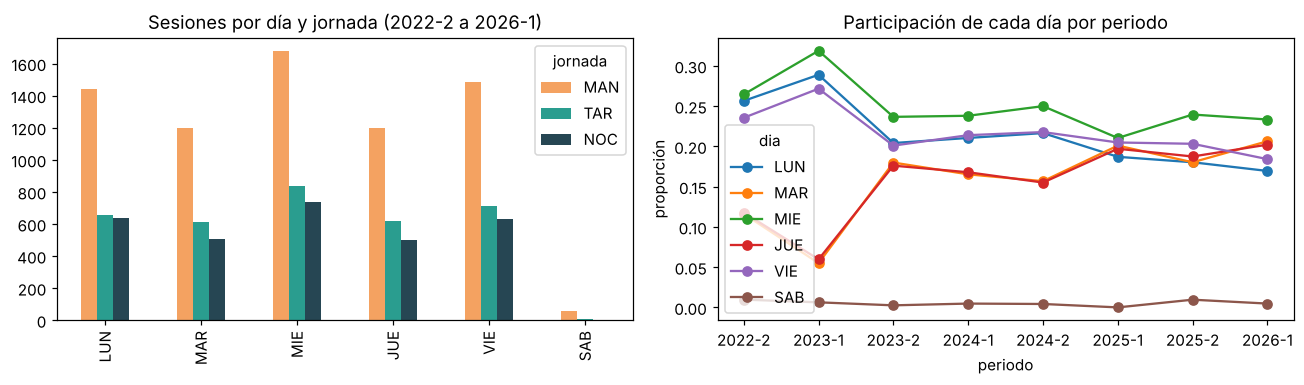

In [4]:
g = grupos.dropna(subset=['hora_ini']).copy()
g = g[g[dias].sum(1).between(1,6)]
g['jornada'] = pd.cut(g.hora_ini, [-1, 11.99, 17.99, 25], labels=['MAN','TAR','NOC']).astype(str)
largo = g.melt(id_vars=['periodo','facultad','cod_materia','creditos','ciclo','jornada','nombre_grupo'],
               value_vars=dias, var_name='dia', value_name='marca')
largo = largo[largo.marca==1].drop(columns='marca')
largo['franja'] = largo.dia + '_' + largo.jornada
fig, ax = plt.subplots(1,2, figsize=(12,3.6))
t = pd.crosstab(largo.dia, largo.jornada).reindex(dias)[['MAN','TAR','NOC']]
t.plot.bar(ax=ax[0], color=['#f4a261','#2a9d8f','#264653']); ax[0].set_title('Sesiones por día y jornada (2022-2 a 2026-1)'); ax[0].set_xlabel('')
p = pd.crosstab(largo.periodo, largo.dia, normalize='index')[dias]
p.plot(ax=ax[1], marker='o'); ax[1].set_title('Participación de cada día por periodo'); ax[1].set_ylabel('proporción')
plt.tight_layout()

**Representatividad:** los datos describen la **oferta** (grupos programados), no la demanda ni la matrícula de estudiantes. Representan pregrado presencial de las tres facultades en Bogotá; no representan virtual, posgrado ni lo que finalmente se canceló por falta de cupo. La noche y el sábado concentran a estudiantes que trabajan: si el modelo falla más allí, perjudica justamente a quienes más necesitan un horario estable (se revisa en la sección 5).

## 3. Preparación y diseño experimental sin fuga
**Unidad de análisis:** (materia, franja, periodo objetivo *t*). **Candidatas:** materias con al menos un grupo en *t-1* o *t-2* **y que abren en *t***. Supuesto de decisión: el estudiante ya sabe qué materias le faltan y la universidad anuncia qué materias abrirá; lo incierto es **cuándo** (día y jornada). Este supuesto no mete información del periodo *t* en las variables: solo define qué filas se evalúan. Las materias con código nuevo (sin historia) quedan fuera del alcance de la herramienta y se gestionan a mano. **Etiqueta:** 1 si la materia tiene grupo en esa franja en *t*.

**Regla anti-fuga:** todas las variables se calculan **solo con periodos anteriores a *t***. Nada del periodo objetivo entra como predictor (ni número de grupos, ni docente, ni aula).

**¿Por qué temporal y no por grupos?** En los retos se partía por grupos (colegio, municipio) porque el modelo debía servir para grupos nuevos. Aquí la herramienta se usa con las **mismas materias** en un **semestre futuro**, así que lo que hay que imitar es el paso del tiempo: se entrena con el pasado y se evalúa en el futuro. La dependencia entre las 18 franjas de una misma materia se respeta en la evaluación con un *bootstrap* que remuestrea materias completas.

**Partición temporal:** entrenamiento y validación cruzada con periodos objetivo 2023-2 a 2025-2 (validación hacia adelante: se entrena con el pasado y se valida en el periodo siguiente); **prueba = 2026-1, consultada una sola vez** al final.

In [5]:
PERIODOS_ORD = sorted(largo.periodo.unique())
FRANJAS = [d+'_'+j for d in dias for j in ['MAN','TAR','NOC']]
# conteo de grupos por materia-franja-periodo
cnt = largo.drop_duplicates(['periodo','cod_materia','nombre_grupo','franja']).groupby(['periodo','cod_materia','franja']).size()
tot_mat = g.drop_duplicates(['periodo','cod_materia','nombre_grupo']).groupby(['periodo','cod_materia']).size()
info_per = g.groupby(['periodo','cod_materia']).agg(facultad=('facultad','first'), creditos=('creditos','median'))   # por periodo: se consulta solo el pasado
ciclo8 = g.assign(c8=g.ciclo.astype(str).str.startswith('C')).groupby(['periodo','cod_materia']).c8.mean()
tasa_franja = largo.groupby(['periodo','franja']).size() / largo.groupby('periodo').size()

def construir(t):
    i = PERIODOS_ORD.index(t); prev = PERIODOS_ORD[:i]
    p1 = prev[-1]; p2 = prev[-2] if len(prev) > 1 else None
    mats = set(tot_mat.loc[p1].index) | (set(tot_mat.loc[p2].index) if p2 else set())
    if t in tot_mat.index.get_level_values(0):        # periodo con programación conocida (entrenamiento/prueba)
        mats &= set(tot_mat.loc[t].index)             # supuesto de decisión: se sabe QUÉ materias abren, no CUÁNDO
    filas = []
    for m in sorted(mats):   # orden fijo: reproducible entre corridas
        hist_p = [p for p in prev if (p, m) in tot_mat.index]
        for f in FRANJAS:
            d_, j_ = f.split('_')
            r = {'periodo': t, 'cod_materia': m, 'franja': f, 'dia': d_, 'jornada': j_}
            r['lag1_franja'] = int(cnt.get((p1, m, f), 0) > 0)
            r['lag2_franja'] = int(cnt.get((p2, m, f), 0) > 0) if p2 else 0
            r['grupos_franja_lag1'] = cnt.get((p1, m, f), 0)
            r['frac_hist_franja'] = np.mean([cnt.get((p, m, f), 0) > 0 for p in hist_p]) if hist_p else 0.0
            r['n_periodos_historia'] = len(hist_p)
            r['ofertada_lag1'] = int((p1, m) in tot_mat.index)
            r['grupos_lag1'] = tot_mat.get((p1, m), 0)
            r['franjas_lag1'] = sum(cnt.get((p1, m, ff), 0) > 0 for ff in FRANJAS)
            r['mismo_dia_otra_jornada_lag1'] = int(any(cnt.get((p1, m, d_+'_'+jj), 0) > 0 for jj in ['MAN','TAR','NOC'] if jj != j_))
            r['misma_jornada_otro_dia_lag1'] = int(any(cnt.get((p1, m, dd+'_'+j_), 0) > 0 for dd in dias if dd != d_))
            r['prop_ciclo8_lag1'] = ciclo8.get((p1, m), np.nan)
            r['tasa_franja_global_lag1'] = tasa_franja.get((p1, f), 0.0)
            r['semestre_objetivo'] = int(t[-1])
            ult = info_per.loc[(hist_p[-1], m)] if hist_p else None          # último periodo ANTERIOR a t en que apareció
            r['facultad'] = ult.facultad if ult is not None else 'NA'; r['creditos'] = ult.creditos if ult is not None else np.nan
            r['y'] = int(cnt.get((t, m, f), 0) > 0)
            filas.append(r)
    return pd.DataFrame(filas)

OBJETIVOS = [p for p in PERIODOS_ORD if p >= '2023-2']
datos = pd.concat([construir(t) for t in OBJETIVOS], ignore_index=True)
datos['prop_ciclo8_lag1'] = datos['prop_ciclo8_lag1'].fillna(-1)   # -1 = sin grupos en t-1 (indicador explícito)
print(datos.shape)
print(datos.groupby('periodo').agg(filas=('y','size'), materias=('cod_materia','nunique'), positivos=('y','sum'), tasa_pos=('y','mean')).round(3))

(21528, 21)
         filas  materias  positivos  tasa_pos
periodo                                      
2023-2    1368        76        327     0.239
2024-1    4914       273       1192     0.243
2024-2    5328       296       1254     0.235
2025-1    3762       209        986     0.262
2025-2    1566        87        425     0.271
2026-1    4590       255       1187     0.259


**Desbalance:** solo ~1 de cada 6 a 10 pares (materia, franja) se abre. **No se re-pondera ni se sobre-muestrea**, a propósito: la app le muestra al estudiante una probabilidad («82 % de que Cálculo abra el martes en la noche») y re-ponderar la infla. El desbalance se trata en la evaluación (PR-AUC, sensible a la clase positiva, en lugar de exactitud) y en la decisión (umbral elegido por costo, calculado solo con validación).

In [6]:
NUM = ['lag1_franja','lag2_franja','grupos_franja_lag1','frac_hist_franja','n_periodos_historia','ofertada_lag1',
       'grupos_lag1','franjas_lag1','mismo_dia_otra_jornada_lag1','misma_jornada_otro_dia_lag1','prop_ciclo8_lag1',
       'tasa_franja_global_lag1','semestre_objetivo','creditos']
CAT = ['dia','jornada','facultad']
X_COLS = NUM + CAT
desarrollo = datos[datos.periodo < '2026-1'].reset_index(drop=True)
prueba = datos[datos.periodo == '2026-1'].reset_index(drop=True)   # NO se toca hasta la sección 5.4
PER_DES = sorted(desarrollo.periodo.unique())
PLIEGUES = [(PER_DES[:k], PER_DES[k]) for k in range(1, len(PER_DES))]   # validación hacia adelante
print('Pliegues (entrena → valida):'); [print(' ', tr, '→', va) for tr, va in PLIEGUES]
print('Prueba:', prueba.shape, '| tasa positiva', round(prueba.y.mean(), 3))

def prepro(escalar=True):
    num = Pipeline([('imp', SimpleImputer(strategy='median'))] + ([('esc', StandardScaler())] if escalar else []))
    return ColumnTransformer([('num', num, NUM), ('cat', OneHotEncoder(handle_unknown='ignore'), CAT)])

Pliegues (entrena → valida):
  ['2023-2'] → 2024-1
  ['2023-2', '2024-1'] → 2024-2
  ['2023-2', '2024-1', '2024-2'] → 2025-1
  ['2023-2', '2024-1', '2024-2', '2025-1'] → 2025-2
Prueba: (4590, 21) | tasa positiva 0.259


## 4. Modelado comparativo con línea base
**Líneas base:** (a) *persistencia* = «la materia vuelve a la franja donde estuvo el semestre pasado» (lo que haría hoy una persona); (b) *frecuencia histórica* = proporción de periodos pasados en que estuvo en esa franja.

**Familias candidatas (mismo diseño, mismos pliegues):** regresión logística (lineal), bosque aleatorio y *gradient boosting* (ensambles de árboles), y perceptrón multicapa (red neuronal). Los hiperparámetros se eligen por el **PR-AUC promedio en validación hacia adelante**; el conjunto de prueba no participa.

In [7]:
CANDIDATOS = {
 'Logística': (lambda h: Pipeline([('pre', prepro()), ('m', LogisticRegression(C=h, max_iter=2000))]), [0.01, 0.1, 1.0]),
 'Bosque aleatorio': (lambda h: Pipeline([('pre', prepro(False)), ('m', RandomForestClassifier(n_estimators=300, min_samples_leaf=h, n_jobs=-1, random_state=SEMILLA))]), [5, 20, 50]),
 'Gradient boosting': (lambda h: Pipeline([('pre', prepro(False)), ('m', HistGradientBoostingClassifier(learning_rate=h, max_iter=200, max_leaf_nodes=15, random_state=SEMILLA))]), [0.03, 0.1]),
 'MLP': (lambda h: Pipeline([('pre', prepro()), ('m', MLPClassifier(hidden_layer_sizes=(32,16), alpha=h, max_iter=300, early_stopping=True, random_state=SEMILLA))]), [1e-3, 1e-1]),
}
def evaluar_cv(fabrica):
    res = []; oof = []
    for tr, va in PLIEGUES:
        dtr = desarrollo[desarrollo.periodo.isin(tr)]; dva = desarrollo[desarrollo.periodo == va]
        mod = fabrica().fit(dtr[X_COLS], dtr.y)
        p_va = mod.predict_proba(dva[X_COLS])[:, 1]; p_tr = mod.predict_proba(dtr[X_COLS])[:, 1]
        res.append({'valida': va, 'pr_auc_val': average_precision_score(dva.y, p_va), 'pr_auc_ent': average_precision_score(dtr.y, p_tr),
                    'roc_auc_val': roc_auc_score(dva.y, p_va)})
        oof.append(pd.DataFrame({'periodo': va, 'y': dva.y.values, 'p': p_va, 'dia': dva.dia.values, 'jornada': dva.jornada.values, 'facultad': dva.facultad.values}))
    return pd.DataFrame(res), pd.concat(oof)

filas = []; OOF = {}
for nombre in ['persistencia', 'frecuencia histórica']:
    col = 'lag1_franja' if nombre == 'persistencia' else 'frac_hist_franja'
    r = []; o = []
    for tr, va in PLIEGUES:
        dva = desarrollo[desarrollo.periodo == va]
        r.append({'valida': va, 'pr_auc_val': average_precision_score(dva.y, dva[col]), 'pr_auc_ent': np.nan, 'roc_auc_val': roc_auc_score(dva.y, dva[col])})
        o.append(pd.DataFrame({'periodo': va, 'y': dva.y.values, 'p': dva[col].values.astype(float), 'dia': dva.dia.values, 'jornada': dva.jornada.values, 'facultad': dva.facultad.values}))
    r = pd.DataFrame(r); OOF[nombre] = pd.concat(o)
    filas.append({'modelo': 'Línea base: ' + nombre, 'hiper': '-', 'pr_auc_val_media': r.pr_auc_val.mean(), 'pr_auc_val_de': r.pr_auc_val.std(), 'pr_auc_ent_media': np.nan, 'roc_auc_val_media': r.roc_auc_val.mean()})
for nombre, (fab, grid) in CANDIDATOS.items():
    for h in grid:
        r, o = evaluar_cv(lambda: fab(h)); OOF[(nombre, h)] = o
        filas.append({'modelo': nombre, 'hiper': h, 'pr_auc_val_media': r.pr_auc_val.mean(), 'pr_auc_val_de': r.pr_auc_val.std(),
                      'pr_auc_ent_media': r.pr_auc_ent.mean(), 'roc_auc_val_media': r.roc_auc_val.mean()})
comparacion = pd.DataFrame(filas)
print(comparacion.round(3).to_string(index=False))

                          modelo  hiper  pr_auc_val_media  pr_auc_val_de  pr_auc_ent_media  roc_auc_val_media
        Línea base: persistencia      -             0.466          0.121               NaN              0.715
Línea base: frecuencia histórica      -             0.538          0.114               NaN              0.768
                       Logística   0.01             0.633          0.175             0.744              0.819
                       Logística    0.1             0.630          0.169             0.746              0.819
                       Logística    1.0             0.630          0.168             0.746              0.818
                Bosque aleatorio      5             0.633          0.159             0.895              0.822
                Bosque aleatorio     20             0.642          0.169             0.817              0.826
                Bosque aleatorio     50             0.640          0.171             0.783              0.825
          

**Criterio de elección declarado:** el mejor PR-AUC medio en validación hacia adelante; si dos modelos quedan a menos de una desviación estándar, se prefiere el más simple e interpretable.

In [8]:
mejores = comparacion[comparacion.hiper != '-'].sort_values('pr_auc_val_media', ascending=False).groupby('modelo').head(1)
print(mejores.round(3).to_string(index=False))
top = mejores.iloc[0]
empatados = mejores[mejores.pr_auc_val_media >= top.pr_auc_val_media - top.pr_auc_val_de]
orden_simple = ['Logística', 'Gradient boosting', 'Bosque aleatorio', 'MLP']
elegido = sorted(empatados.modelo, key=orden_simple.index)[0]
h_elegido = mejores.set_index('modelo').loc[elegido, 'hiper']
print(f'\nModelo final elegido: {elegido} (hiperparámetro = {h_elegido})')
print('Modelos dentro de 1 DE del mejor:', list(empatados.modelo))

           modelo hiper  pr_auc_val_media  pr_auc_val_de  pr_auc_ent_media  roc_auc_val_media
 Bosque aleatorio    20             0.642          0.169             0.817              0.826
        Logística  0.01             0.633          0.175             0.744              0.819
Gradient boosting  0.03             0.623          0.141             0.857              0.809
              MLP   0.1             0.609          0.133             0.776              0.791

Modelo final elegido: Logística (hiperparámetro = 0.01)
Modelos dentro de 1 DE del mejor: ['Bosque aleatorio', 'Logística', 'Gradient boosting', 'MLP']


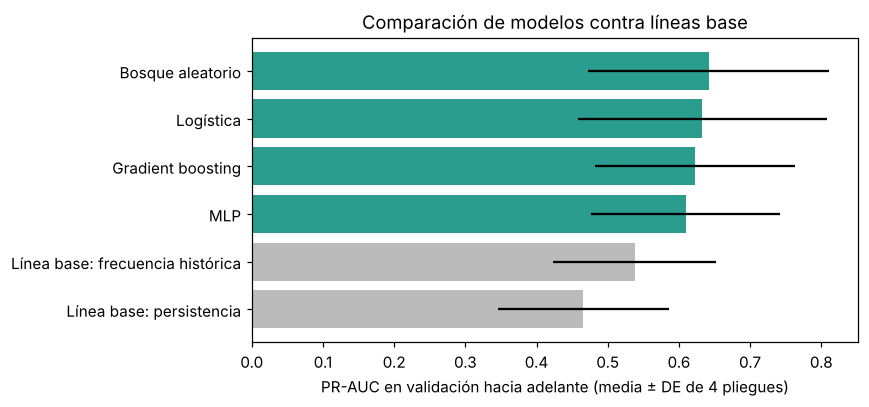

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
cmp_plot = comparacion.sort_values('pr_auc_val_media').groupby('modelo').tail(1).sort_values('pr_auc_val_media')
ax.barh(cmp_plot.modelo, cmp_plot.pr_auc_val_media, xerr=cmp_plot.pr_auc_val_de, color=['#bbb' if 'base' in m else '#2a9d8f' for m in cmp_plot.modelo])
ax.set_xlabel('PR-AUC en validación hacia adelante (media ± DE de 4 pliegues)'); ax.set_title('Comparación de modelos contra líneas base')
plt.tight_layout()

**Diagnóstico de sesgo y varianza:** la columna `pr_auc_ent_media` frente a `pr_auc_val_media` muestra la brecha entrenamiento–validación. Una brecha grande (bosque con hojas pequeñas, MLP) indica varianza; si entrenamiento y validación son bajos y parecidos, el límite es de sesgo o de información (la programación cambia por razones que no están en los datos: docentes, aulas, demanda).

In [10]:
brecha = mejores.assign(brecha=mejores.pr_auc_ent_media - mejores.pr_auc_val_media)[['modelo','hiper','pr_auc_ent_media','pr_auc_val_media','brecha']]
print(brecha.round(3).to_string(index=False))

           modelo hiper  pr_auc_ent_media  pr_auc_val_media  brecha
 Bosque aleatorio    20             0.817             0.642   0.175
        Logística  0.01             0.744             0.633   0.111
Gradient boosting  0.03             0.857             0.623   0.234
              MLP   0.1             0.776             0.609   0.167


## 5. Evaluación según el costo del error
### 5.1 Umbral de decisión con costo FP:FN = 2:1 y análisis de sensibilidad
El umbral se elige sobre las predicciones fuera de pliegue (validación), nunca sobre la prueba.

Umbral elegido: 0.71 | costo/100 decisiones (validación): modelo 22.65 vs persistencia 26.55 vs no reservar nada 24.77
FP:FN  umbral  costo_modelo  costo_persistencia  costo_no_reservar  reservas_%
  1:1    0.45         18.36               18.28              24.77       19.96
  2:1    0.71         22.65               26.55              24.77       11.33
  3:1    0.96         23.68               34.82              24.77        2.25
  5:1    0.96         24.26               51.37              24.77        2.25


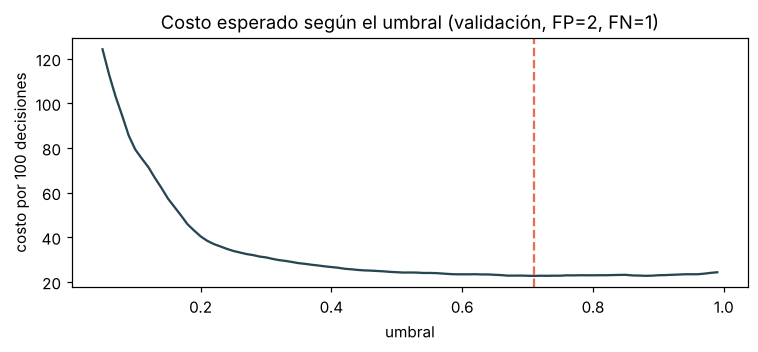

In [11]:
C_FP, C_FN = 2, 1
oof = OOF[(elegido, h_elegido)]
def costo(y, p, u, cfp=None):
    cfp = C_FP if cfp is None else cfp
    pred = (p >= u).astype(int)
    fp = ((pred == 1) & (y == 0)).sum(); fn = ((pred == 0) & (y == 1)).sum()
    return (cfp*fp + C_FN*fn) / len(y) * 100
umbrales = np.round(np.arange(0.05, 0.996, 0.01), 2)
curva = pd.DataFrame({'u': umbrales, 'costo100': [costo(oof.y.values, oof.p.values, u) for u in umbrales]})
U = float(curva.loc[curva.costo100.idxmin(), 'u'])
base_val = OOF['persistencia']
print(f'Umbral elegido: {U:.2f} | costo/100 decisiones (validación): modelo {curva.costo100.min():.2f} vs persistencia {costo(base_val.y.values, base_val.p.values, 0.5):.2f} vs no reservar nada {costo(base_val.y.values, np.zeros(len(base_val)), 0.5):.2f}')
fig, ax = plt.subplots(figsize=(7, 3.3)); ax.plot(curva.u, curva.costo100, color='#264653'); ax.axvline(U, ls='--', color='#e76f51')
ax.set_xlabel('umbral'); ax.set_ylabel('costo por 100 decisiones'); ax.set_title('Costo esperado según el umbral (validación, FP=2, FN=1)'); plt.tight_layout()
sens = []
for r in [1, 2, 3, 5]:
    cs = [costo(oof.y.values, oof.p.values, u, r) for u in umbrales]; k = int(np.argmin(cs))
    sens.append({'FP:FN': f'{r}:1', 'umbral': umbrales[k], 'costo_modelo': cs[k], 'costo_persistencia': costo(base_val.y.values, base_val.p.values, 0.5, r),
                 'costo_no_reservar': costo(base_val.y.values, np.zeros(len(base_val)), 0.5, r), 'reservas_%': ((oof.p.values >= umbrales[k]).mean()*100)})
print(pd.DataFrame(sens).round(2).to_string(index=False))

### 5.2 Estabilidad entre pliegues

In [12]:
def metricas(y, p, u):
    pred = (p >= u).astype(int)
    return {'pr_auc': average_precision_score(y, p), 'precision': precision_score(y, pred, zero_division=0), 'recall': recall_score(y, pred), 'f1': f1_score(y, pred), 'costo100': costo(y, p, u)}
est = []
for per, d in oof.groupby('periodo'):
    b = base_val[base_val.periodo == per]
    est.append({'valida': per, **{k+'_modelo': v for k, v in metricas(d.y.values, d.p.values, U).items()}, **{k+'_persist': v for k, v in metricas(b.y.values, b.p.values, 0.5).items()}})
est = pd.DataFrame(est)
print(est[['valida','pr_auc_modelo','pr_auc_persist','precision_modelo','precision_persist','recall_modelo','recall_persist','costo100_modelo','costo100_persist']].round(3).to_string(index=False))
print('\nMedia ± DE del costo/100 – modelo:', round(est.costo100_modelo.mean(), 2), '±', round(est.costo100_modelo.std(), 2), '| persistencia:', round(est.costo100_persist.mean(), 2), '±', round(est.costo100_persist.std(), 2))

valida  pr_auc_modelo  pr_auc_persist  precision_modelo  precision_persist  recall_modelo  recall_persist  costo100_modelo  costo100_persist
2024-1          0.766           0.544             0.975              0.741          0.130           0.606           21.266            19.862
2024-2          0.793           0.590             0.864              0.732          0.506           0.713           15.390            19.032
2025-1          0.538           0.395             0.589              0.524          0.426           0.507           30.622            37.055
2025-2          0.435           0.335             0.487              0.419          0.181           0.431           32.567            47.893

Media ± DE del costo/100 – modelo: 24.96 ± 8.07 | persistencia: 30.96 ± 14.02


### 5.3 Modelo final: se reentrena con todo el desarrollo (2023-2 a 2025-2)

In [13]:
fab_final = CANDIDATOS[elegido][0]
modelo_final = fab_final(h_elegido).fit(desarrollo[X_COLS], desarrollo.y)
os.makedirs('modelo', exist_ok=True)
joblib.dump({'modelo': modelo_final, 'umbral': U, 'X_COLS': X_COLS, 'nombre': elegido, 'hiper': h_elegido}, 'modelo/modelo_horario.joblib')
print('Modelo guardado en modelo/modelo_horario.joblib')

Modelo guardado en modelo/modelo_horario.joblib


### 5.4 Prueba (2026-1), consultada una sola vez
Se reporta con intervalo de confianza por *bootstrap* de materias (se remuestrean materias completas, porque las 18 franjas de una materia no son independientes).

In [14]:
p_test = modelo_final.predict_proba(prueba[X_COLS])[:, 1]
m_mod = metricas(prueba.y.values, p_test, U); m_base = metricas(prueba.y.values, prueba.lag1_franja.values.astype(float), 0.5)
m_nada = {'pr_auc': np.nan, 'precision': np.nan, 'recall': 0.0, 'f1': 0.0, 'costo100': costo(prueba.y.values, np.zeros(len(prueba)), 0.5)}
rng = np.random.default_rng(SEMILLA); mats = prueba.cod_materia.unique(); idx_m = prueba.groupby('cod_materia').indices
boot = []
for _ in range(500):
    s = np.concatenate([idx_m[m] for m in rng.choice(mats, len(mats), replace=True)])
    y_ = prueba.y.values[s]
    boot.append({'pr_auc': average_precision_score(y_, p_test[s]), 'costo_mod': costo(y_, p_test[s], U), 'costo_base': costo(y_, prueba.lag1_franja.values[s].astype(float), 0.5),
                 'prec_mod': precision_score(y_, (p_test[s] >= U).astype(int), zero_division=0)})
boot = pd.DataFrame(boot); boot['ahorro'] = boot.costo_base - boot.costo_mod
ic = lambda c: f'[{boot[c].quantile(.025):.3f}; {boot[c].quantile(.975):.3f}]'
print('PRUEBA 2026-1')
print(pd.DataFrame({'modelo': m_mod, 'persistencia': m_base, 'no reservar nada': m_nada}).round(3).to_string())
print('IC95% PR-AUC modelo:', ic('pr_auc'), '| IC95% precisión modelo:', ic('prec_mod'))
print('IC95% costo/100 modelo:', ic('costo_mod'), '| persistencia:', ic('costo_base'))
print('IC95% ahorro (persistencia − modelo) por 100 decisiones:', ic('ahorro'), '| P(ahorro>0) =', round((boot.ahorro > 0).mean(), 3))
print('Brier modelo:', round(brier_score_loss(prueba.y, p_test), 4))
print('Costo/100 de no reservar nada (status quo manual):', round(m_nada['costo100'], 2))
# calibración: ¿la probabilidad que verá el estudiante coincide con la frecuencia real?
cal = pd.DataFrame({'p': p_test, 'y': prueba.y}).assign(tramo=lambda d: pd.cut(d.p, [0, .1, .3, .5, .7, .9, 1.0], include_lowest=True))
print('\nCalibración en prueba:'); print(cal.groupby('tramo', observed=True).agg(n=('y','size'), p_media=('p','mean'), tasa_real=('y','mean')).round(3).to_string())

PRUEBA 2026-1
           modelo  persistencia  no reservar nada
pr_auc      0.830         0.732               NaN
precision   0.904         0.827               NaN
recall      0.347         0.832             0.000
f1          0.502         0.830             0.000
costo100   18.802        13.355            25.861
IC95% PR-AUC modelo: [0.789; 0.868] | IC95% precisión modelo: [0.864; 0.943]
IC95% costo/100 modelo: [17.440; 20.492] | persistencia: [10.958; 15.764]
IC95% ahorro (persistencia − modelo) por 100 decisiones: [-7.603; -3.627] | P(ahorro>0) = 0.0
Brier modelo: 0.0912
Costo/100 de no reservar nada (status quo manual): 25.86

Calibración en prueba:
                  n  p_media  tasa_real
tramo                                  
(-0.001, 0.1]  1323    0.054      0.013
(0.1, 0.3]     1950    0.163      0.087
(0.3, 0.5]      306    0.417      0.484
(0.5, 0.7]      509    0.606      0.796
(0.7, 0.9]      479    0.767      0.885
(0.9, 1.0]       23    0.937      1.000


### 5.5 ¿A quién le funciona peor? Errores por día, jornada y facultad (prueba)

In [15]:
prueba_ev = prueba.assign(p=p_test, pred=(p_test >= U).astype(int))
def tabla_grupo(col):
    return prueba_ev.groupby(col).apply(lambda d: pd.Series({'n': len(d), 'tasa_real': d.y.mean(), 'precision': precision_score(d.y, d.pred, zero_division=0),
                                                              'recall': recall_score(d.y, d.pred, zero_division=0), 'costo100': costo(d.y.values, d.p.values, U)})).round(3)
for c in ['jornada', 'dia', 'facultad']:
    print(tabla_grupo(c).to_string(), '\n')

              n  tasa_real  precision  recall  costo100
jornada                                                
MAN      1530.0      0.311      0.935   0.363    21.373
NOC      1530.0      0.186      0.864   0.200    16.078
TAR      1530.0      0.278      0.888   0.427    18.954 

         n  tasa_real  precision  recall  costo100
dia                                               
JUE  765.0      0.314      0.940   0.329    22.353
LUN  765.0      0.264      0.864   0.252    21.830
MAR  765.0      0.322      0.947   0.293    23.791
MIE  765.0      0.350      0.871   0.451    23.922
SAB  765.0      0.010      0.000   0.000     1.046
VIE  765.0      0.292      0.908   0.399    19.869 

               n  tasa_real  precision  recall  costo100
facultad                                                
FAFCE     1728.0      0.279      0.907   0.324    20.718
FHCS      1494.0      0.212      0.815   0.237    18.407
FIN       1368.0      0.284      0.943   0.465    16.813 



**Sensibilidad (5.1):** si el costo de un falso positivo es 3 veces o más el de un falso negativo, el umbral óptimo sube tanto que el modelo casi no reserva y empata con «no reservar nada»: en ese escenario la herramienta solo debe *sugerir*, no reservar.

**Lectura:** el sábado casi no tiene oferta presencial de pregrado (≈1 % de los grupos en todos los periodos; 10 grupos en 2026-1). Con tan pocos casos el modelo **nunca** pre-reserva un sábado: para el caso que motivó la idea, la herramienta debe avisar «revisar a mano», no prometer. La noche tiene el menor *recall*: a los estudiantes que trabajan les reserva menos de lo que podría, aunque con buena precisión.

### 5.6 Qué aprendió el modelo (importancia por permutación en validación 2025-2, no en prueba)

frac_hist_franja               0.0493
grupos_lag1                    0.0071
creditos                       0.0036
mismo_dia_otra_jornada_lag1    0.0034
grupos_franja_lag1             0.0030
dia                            0.0020
facultad                       0.0019
ofertada_lag1                  0.0017
lag2_franja                    0.0016
misma_jornada_otro_dia_lag1    0.0012
semestre_objetivo              0.0000
jornada                       -0.0002
control_aleatoria             -0.0002
franjas_lag1                  -0.0011
lag1_franja                   -0.0013
n_periodos_historia           -0.0047
tasa_franja_global_lag1       -0.0049
prop_ciclo8_lag1              -0.0056
Variables por encima de la columna de control: 12 de 17


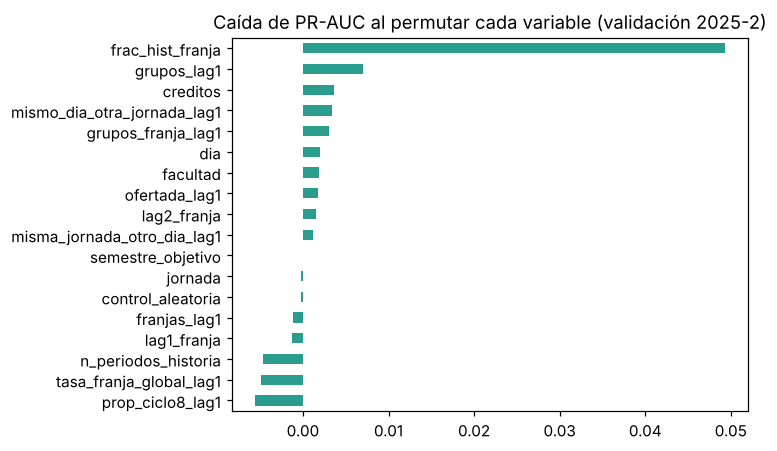

In [16]:
from sklearn.inspection import permutation_importance
tr, va = PLIEGUES[-1]
# columna de control: ruido aleatorio sin relación con el objetivo; una variable que no supere su importancia no aporta
rng_c = np.random.default_rng(SEMILLA)
d_imp = desarrollo.assign(control_aleatoria=rng_c.normal(size=len(desarrollo)))
NUM_C = NUM + ['control_aleatoria']
pre_c = ColumnTransformer([('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('esc', StandardScaler())]), NUM_C), ('cat', OneHotEncoder(handle_unknown='ignore'), CAT)])
m_tmp = Pipeline([('pre', pre_c), ('m', LogisticRegression(C=h_elegido, max_iter=2000))]).fit(d_imp[d_imp.periodo.isin(tr)][NUM_C + CAT], d_imp[d_imp.periodo.isin(tr)].y)
dva = d_imp[d_imp.periodo == va]
imp = permutation_importance(m_tmp, dva[NUM_C + CAT], dva.y, scoring='average_precision', n_repeats=5, random_state=SEMILLA, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=NUM_C + CAT).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.2)); imp.plot.barh(ax=ax, color='#2a9d8f'); ax.set_title('Caída de PR-AUC al permutar cada variable (validación 2025-2)'); plt.tight_layout()
print(imp.sort_values(ascending=False).round(4).to_string())
print('Variables por encima de la columna de control:', int((imp > imp['control_aleatoria']).sum()), 'de', len(imp) - 1)

Estas importancias describen **asociaciones**: que «haber estado el sábado el semestre pasado» pese mucho no significa que eso *cause* la programación; refleja inercia administrativa (mismo docente, misma aula, misma cohorte).

## 6. Despliegue: del modelo al horario del estudiante
El recomendador toma el horario actual del estudiante, lo convierte en un **perfil de franjas preferidas** y, para cada materia pendiente, propone la franja preferida con mayor probabilidad de abrirse, **solo si supera el umbral** y no choca con otra materia ya reservada. Abajo se predice **2026-2** (casos nuevos, sin etiqueta todavía) con historia hasta 2026-1.

In [17]:
def construir_futuro(t_nuevo='2026-2'):
    global PERIODOS_ORD
    original = PERIODOS_ORD; PERIODOS_ORD = original + [t_nuevo]
    try: df = construir(t_nuevo)
    finally: PERIODOS_ORD = original
    df['prop_ciclo8_lag1'] = df['prop_ciclo8_lag1'].fillna(-1)
    return df.drop(columns='y')
futuro = construir_futuro()
modelo_desp = fab_final(h_elegido).fit(datos[X_COLS], datos.y)   # mismo modelo y hiperparámetro; para operar se reentrena sumando 2026-1, ya evaluado
futuro['p'] = modelo_desp.predict_proba(futuro[X_COLS])[:, 1]
nombres = g.sort_values('periodo').assign(nom=lambda d: d.nombre_grupo.astype(str).map(norm).str.replace(r'\s+[CS]\dG\d+\s*$', '', regex=True)).groupby('cod_materia').nom.last()
futuro['materia'] = futuro.cod_materia.map(nombres)
joblib.dump({'modelo': modelo_desp, 'umbral': U, 'X_COLS': X_COLS, 'nombre': elegido, 'hiper': h_elegido}, 'modelo/modelo_horario_operacion.joblib')
futuro[['cod_materia','materia','franja','dia','jornada','p']].to_csv('modelo/predicciones_2026-2.csv', index=False)
futuro[['cod_materia','materia','franja'] + X_COLS].to_csv('modelo/variables_2026-2.csv', index=False)   # entrada del servicio app.py
print(futuro.shape, '→ modelo/predicciones_2026-2.csv')

def recomendar(franjas_actuales, materias_pendientes, pred=futuro, umbral=U):
    """franjas_actuales: lista como ['SAB_MAN','MAR_NOC']; materias_pendientes: lista de códigos."""
    perfil = set(franjas_actuales); usadas = set(); salida = []
    for m in materias_pendientes:
        c = pred[(pred.cod_materia == m)].sort_values('p', ascending=False)
        pref = c[c.franja.isin(perfil) & ~c.franja.isin(usadas) & ~c.franja.str.startswith('SAB')]   # sábados fuera ANTES de elegir
        if len(pref) and pref.iloc[0].p >= umbral:
            r = pref.iloc[0]; usadas.add(r.franja); salida.append({'materia': r.materia, 'franja': r.franja, 'prob': round(r.p, 2), 'accion': 'PRE-RESERVAR'})
        else:
            alt = c[~c.franja.isin(usadas)].head(1)
            salida.append({'materia': nombres.get(m, m), 'franja': alt.franja.iloc[0] if len(alt) else '-', 'prob': round(alt.p.iloc[0], 2) if len(alt) else np.nan,
                           'accion': 'SUGERIR: revisar a mano (fuera de su patrón, sábado o poco segura)'})
    return pd.DataFrame(salida)

# Ejemplo: estudiante que trabaja entre semana y estudia sábados en la mañana y martes/jueves en la noche
sab = futuro[futuro.franja == 'SAB_MAN'].sort_values('p', ascending=False).cod_materia.head(3).tolist()
noc = futuro[futuro.franja.isin(['MAR_NOC','JUE_NOC'])].sort_values('p', ascending=False).cod_materia.drop_duplicates().head(2).tolist()
otra = futuro[(futuro.franja == 'LUN_MAN')].sort_values('p', ascending=False).cod_materia.head(1).tolist()
print(recomendar(['SAB_MAN', 'MAR_NOC', 'JUE_NOC'], sab + noc + otra).to_string(index=False))

(8046, 22) → modelo/predicciones_2026-2.csv
                 materia  franja  prob                                                             accion
METOD AVANZ DE INV APLIC JUE_TAR  0.57 SUGERIR: revisar a mano (fuera de su patrón, sábado o poco segura)
APLICAC DE MODELOS ESTAD JUE_TAR  0.57 SUGERIR: revisar a mano (fuera de su patrón, sábado o poco segura)
         METOD DE INVEST JUE_TAR  0.57 SUGERIR: revisar a mano (fuera de su patrón, sábado o poco segura)
        CALCULO INTEGRAL MAR_NOC  0.82                                                       PRE-RESERVAR
     CALCULO DIFERENCIAL JUE_NOC  0.80                                                       PRE-RESERVAR
   EL PODER DE LAS PROBA MIE_MAN  0.98 SUGERIR: revisar a mano (fuera de su patrón, sábado o poco segura)


**Para operarlo de verdad:** cada semestre, al publicarse la programación oficial, se compara lo pre-reservado con lo que se abrió (precisión real de las reservas). Si la precisión cae por debajo de la de la regla de persistencia durante un periodo, o si cambia el catálogo de códigos, se reentrena con el periodo nuevo. El modelo **sugiere**; la reserva definitiva la confirma el estudiante o Registro.

## 7. Validación prospectiva con 2026-2 (después de la entrega)
Las predicciones de 2026-2 de la sección 6 quedaron guardadas en `modelo/predicciones_2026-2.csv` **antes** de conocer la programación de 2026-2. Después se descargó la programación oficial de 2026-2 del portal de la EAN (carpeta `datos_validacion/`). Del archivo se quitó solo la hoja consolidada `PRE-PRES` (más de un millón de filas vacías, unos 20 MB) para respetar el límite de tamaño de GitHub; las hojas por facultad, que son las que se leen, quedan intactas. Aquí se compara lo predicho con lo que de verdad se abrió. **Nada del modelo ni del umbral se cambia:** es una segunda prueba, con datos que el modelo nunca vio.

Se aplica el mismo supuesto de decisión: se evalúan las materias con historia que abren en 2026-2.

In [18]:
RUTA_VAL = 'datos_validacion/Programacion_PREGRADO_PRESENCIAL_2026-2.xlsx'
val = pd.concat([leer_hoja(RUTA_VAL, h, '2026-2') for h in FACULTADES], ignore_index=True)
val['cod_materia'] = val['codigo_raw'].astype(str).str.strip().str.upper().str[:8]
gv = val.dropna(subset=['hora_ini']); gv = gv[gv[dias].sum(1).between(1, 6)].copy()
gv['jornada'] = pd.cut(gv.hora_ini, [-1, 11.99, 17.99, 25], labels=['MAN','TAR','NOC']).astype(str)
lv = gv.melt(id_vars=['cod_materia','jornada'], value_vars=dias, var_name='dia', value_name='m'); lv = lv[lv.m == 1]
abiertas_v = set(zip(lv.cod_materia, lv.dia + '_' + lv.jornada)); mats_v = set(gv.cod_materia)
ev = futuro[futuro.cod_materia.isin(mats_v)].copy()
ev['y'] = [int((m, f) in abiertas_v) for m, f in zip(ev.cod_materia, ev.franja)]
print('Grupos 2026-2:', len(val), '| materias que abren:', len(mats_v), '| con historia (evaluables):', ev.cod_materia.nunique(),
      '| sin historia (fuera de alcance):', len(mats_v - set(futuro.cod_materia)))
print('Pares evaluados:', len(ev), '| tasa real de apertura:', round(ev.y.mean(), 3), '| sesiones de sábado en 2026-2:', int(lv.dia.eq('SAB').sum()))
m_v = metricas(ev.y.values, ev.p.values, U); b_v = metricas(ev.y.values, ev.lag1_franja.values.astype(float), 0.5)
n_v = {'pr_auc': np.nan, 'precision': np.nan, 'recall': 0.0, 'f1': 0.0, 'costo100': costo(ev.y.values, np.zeros(len(ev)), 0.5)}
print('\nVALIDACIÓN 2026-2 (umbral', U, 'fijado en validación, sin cambios)')
print(pd.DataFrame({'modelo': m_v, 'persistencia': b_v, 'no reservar nada': n_v}).round(3).to_string())
idx_v = ev.reset_index(drop=True).groupby('cod_materia').indices; ms_v = list(idx_v); evr = ev.reset_index(drop=True)
rng = np.random.default_rng(SEMILLA); bv = []
for _ in range(500):
    s = np.concatenate([idx_v[m] for m in rng.choice(ms_v, len(ms_v), replace=True)]); y_ = evr.y.values[s]
    bv.append({'pr_auc': average_precision_score(y_, evr.p.values[s]), 'prec': precision_score(y_, (evr.p.values[s] >= U).astype(int), zero_division=0),
               'ahorro': costo(y_, evr.lag1_franja.values[s].astype(float), 0.5) - costo(y_, evr.p.values[s], U)})
bv = pd.DataFrame(bv); icv = lambda c: f'[{bv[c].quantile(.025):.3f}; {bv[c].quantile(.975):.3f}]'
print('IC95% PR-AUC:', icv('pr_auc'), '| IC95% precisión:', icv('prec'), '| IC95% ahorro (persistencia − modelo) por 100 decisiones:', icv('ahorro'))
calv = ev.assign(tramo=pd.cut(ev.p, [0, .3, .5, .7, 1.0], include_lowest=True)).groupby('tramo', observed=True).agg(n=('y','size'), p_media=('p','mean'), tasa_real=('y','mean'))
print('\nCalibración en 2026-2:'); print(calv.round(3).to_string())
print('\nEjemplo del informe:'); print(ev[ev.franja.isin(['MAR_NOC','JUE_NOC']) & ev.materia.isin(['CALCULO INTEGRAL','CALCULO DIFERENCIAL'])][['materia','franja','p','y']].round(2).to_string(index=False))
ev_g = ev.assign(pred=(ev.p >= U).astype(int)).groupby('jornada').apply(lambda d: pd.Series({'tasa_real': d.y.mean(), 'precision': precision_score(d.y, d.pred, zero_division=0), 'recall': recall_score(d.y, d.pred, zero_division=0)}))
print('\nPor jornada:'); print(ev_g.round(3).to_string())

Grupos 2026-2: 1212 | materias que abren: 298 | con historia (evaluables): 279 | sin historia (fuera de alcance): 19
Pares evaluados: 5022 | tasa real de apertura: 0.26 | sesiones de sábado en 2026-2: 0

VALIDACIÓN 2026-2 (umbral 0.71 fijado en validación, sin cambios)
           modelo  persistencia  no reservar nada
pr_auc      0.689         0.483               NaN
precision   0.776         0.633               NaN
recall      0.335         0.599             0.000
f1          0.468         0.616             0.000
costo100   22.322        28.475            26.006
IC95% PR-AUC: [0.643; 0.738] | IC95% precisión: [0.724; 0.829] | IC95% ahorro (persistencia − modelo) por 100 decisiones: [3.842; 8.323]

Calibración en 2026-2:
                  n  p_media  tasa_real
tramo                                  
(-0.001, 0.3]  3689    0.096      0.126
(0.3, 0.5]      267    0.403      0.479
(0.5, 0.7]      474    0.611      0.544
(0.7, 1.0]      592    0.799      0.769

Ejemplo del informe:
       

**Lectura.** Con dos semestres de prueba la conclusión es más sólida que con uno. En 2026-1 la regla de persistencia tuvo menor costo; en 2026-2, con el mismo modelo y el mismo umbral, el modelo tuvo menor costo que la persistencia y que no reservar. En ambos semestres el modelo ordenó mejor (mayor PR-AUC) y sus reservas fueron más precisas. 2026-2 tampoco tuvo sesiones presenciales de pregrado el sábado, lo que respalda la regla de enviar los sábados a revisión manual.